# YouTube Multi-Channel Analytics – Step-by-Step Python Project

**Goal:** Clean a raw YouTube video dataset, analyze views, likes, comments and engagement rate across channels, create charts, and export the cleaned data.

**Before you start:** Keep `YouTube_Multi_Channel_Analytics.xlsx` in the same folder as this notebook.

If needed, install packages in a notebook cell: `%pip install pandas matplotlib openpyxl`

**Note:** The workbook contains DEMO / SAMPLE data for learning, not real YouTube statistics.

## Step 1 – Import libraries
Pandas handles tabular data. Matplotlib creates charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Step 2 – Load the Excel file
Run this cell and check that the file is in the same folder as the notebook. The raw data is in the `Video_Data` sheet.

In [2]:
df = pd.read_excel("YouTube_Multi_Channel_Analytics.xlsx", sheet_name="Video_Data")

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully
Rows and columns: (50, 9)


,Video_ID,Channel_Name,Video_Title,Category,Published_Date,Views,Likes,Comments,Engagement_Rate_%
0,DEMO0101,TechWorld India,Top 5 AI tools for students,Howto & Style,2026-01-01,28725,1944,106,7.136641
1,DEMO0102,TechWorld India,Python basics explained,Education,2026-01-14,109973,6965,1189,7.414547
2,DEMO0103,TechWorld India,Laptop buying guide,Education,2026-01-27,444917,8955,903,2.215694
3,DEMO0104,TechWorld India,What is cloud computing?,Science & Technology,2026-02-09,633762,12534,2019,2.296288
4,DEMO0105,TechWorld India,Best coding habits,Howto & Style,2026-02-22,573912,26461,3409,5.204631


## Step 3 – Understand the dataset
Inspect column names, data types, missing values, and summary statistics.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all"))

Column names:
['Video_ID', 'Channel_Name', 'Video_Title', 'Category', 'Published_Date', 'Views', 'Likes', 'Comments', 'Engagement_Rate_%']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Video_ID           50 non-null     str           
 1   Channel_Name       50 non-null     str           
 2   Video_Title        50 non-null     str           
 3   Category           50 non-null     str           
 4   Published_Date     50 non-null     datetime64[us]
 5   Views              50 non-null     int64         
 6   Likes              50 non-null     int64         
 7   Comments           50 non-null     int64         
 8   Engagement_Rate_%  50 non-null     float64       
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 3.6 KB

Summary statistics:


,Video_ID,Channel_Name,Video_Title,Category,Published_Date,Views,Likes,Comments,Engagement_Rate_%
count,50,50,50,50,50,50.000000,50.00000,50.000000,50.000000
unique,50,10,50,8,NaN,NaN,NaN,NaN,NaN
top,DEMO0101,TechWorld India,Top 5 AI tools for students,Education,NaN,NaN,NaN,NaN,NaN
freq,1,5,1,11,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2026-03-08 12:00:00,472073.180000,23733.62000,2925.920000,5.671362
min,NaN,NaN,NaN,NaN,2026-01-01 00:00:00,28725.000000,1944.00000,106.000000,2.215694
25%,NaN,NaN,NaN,NaN,2026-02-14 06:00:00,209882.500000,9200.75000,1090.000000,3.692876
50%,NaN,NaN,NaN,NaN,2026-03-08 12:00:00,536078.000000,18134.50000,2426.000000,5.809497
75%,NaN,NaN,NaN,NaN,2026-03-30 18:00:00,671255.750000,34017.00000,3813.250000,7.398660
max,NaN,NaN,NaN,NaN,2026-05-14 00:00:00,917312.000000,65354.00000,10648.000000,9.441566


## Step 4 – Check duplicate records
Count exact duplicate rows, and also repeated `Video_ID` values, before removing them.

In [4]:
duplicate_count = df.duplicated().sum()
duplicate_ids = df["Video_ID"].duplicated().sum()

print("Exact duplicate rows:", duplicate_count)
print("Repeated Video_ID values:", duplicate_ids)

Exact duplicate rows: 0
Repeated Video_ID values: 0


## Step 5 – Remove exact duplicates
Keep the first occurrence of each fully identical row. Then keep only one row per `Video_ID`.

In [5]:
df = df.drop_duplicates().copy()
df = df.drop_duplicates(subset="Video_ID", keep="first").copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (50, 9)


## Step 6 – Clean text columns
Remove leading/trailing spaces and extra spaces between words.

We do **not** use `.str.title()` here (unlike many sales datasets), because it would change names like `TechWorld India` to `Techworld India`.

In [6]:
for column in ["Channel_Name", "Video_Title", "Category"]:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print(df[["Channel_Name", "Category"]].nunique())

Channel_Name    10
Category         8
dtype: int64


## Step 7 – Correct data types
Convert dates and numeric columns. Values that cannot be converted become missing (`NaT` or `NaN`).

In [7]:
df["Published_Date"] = pd.to_datetime(df["Published_Date"], errors="coerce")
df["Views"] = pd.to_numeric(df["Views"], errors="coerce")
df["Likes"] = pd.to_numeric(df["Likes"], errors="coerce")
df["Comments"] = pd.to_numeric(df["Comments"], errors="coerce")
df["Engagement_Rate_%"] = pd.to_numeric(df["Engagement_Rate_%"], errors="coerce")

print(df.dtypes)

Video_ID                        str
Channel_Name                 string
Video_Title                  string
Category                     string
Published_Date       datetime64[us]
Views                         int64
Likes                         int64
Comments                      int64
Engagement_Rate_%           float64
dtype: object


## Step 8 – Check missing values
Count the missing values in each column before deciding how to handle them.

In [8]:
display(df.isnull().sum())

Video_ID             0
Channel_Name         0
Video_Title          0
Category             0
Published_Date       0
Views                0
Likes                0
Comments             0
Engagement_Rate_%    0
dtype: int64

## Step 9 – Handle missing values
Rows missing a key field (date, channel, category, views, likes, comments) cannot be analysed reliably, so we remove them. A missing `Video_Title` is filled with "Unknown".

In [9]:
rows_before = len(df)

df = df.dropna(
    subset=["Published_Date", "Channel_Name", "Category", "Views", "Likes", "Comments"]
).copy()

df["Views"] = df["Views"].astype(int)
df["Likes"] = df["Likes"].astype(int)
df["Comments"] = df["Comments"].astype(int)
df["Video_Title"] = df["Video_Title"].fillna("Unknown")

print("Rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))
display(df.isnull().sum())

Rows removed: 0
Rows remaining: 50


Video_ID             0
Channel_Name         0
Video_Title          0
Category             0
Published_Date       0
Views                0
Likes                0
Comments             0
Engagement_Rate_%    0
dtype: int64

## Step 10 – Create an engagement rate column
Engagement Rate (%) = (Likes + Comments) / Views × 100.
We recalculate it and compare with the value already in the file.

In [10]:
df["Engagement_Calc_%"] = (df["Likes"] + df["Comments"]) / df["Views"] * 100

matches = (df["Engagement_Calc_%"] - df["Engagement_Rate_%"]).abs().max() < 0.01
print("Recalculated engagement matches the original column:", matches)

display(df.head())

Recalculated engagement matches the original column: True


,Video_ID,Channel_Name,Video_Title,Category,Published_Date,Views,Likes,Comments,Engagement_Rate_%,Engagement_Calc_%
0,DEMO0101,TechWorld India,Top 5 AI tools for students,Howto & Style,2026-01-01,28725,1944,106,7.136641,7.136641
1,DEMO0102,TechWorld India,Python basics explained,Education,2026-01-14,109973,6965,1189,7.414547,7.414547
2,DEMO0103,TechWorld India,Laptop buying guide,Education,2026-01-27,444917,8955,903,2.215694,2.215694
3,DEMO0104,TechWorld India,What is cloud computing?,Science & Technology,2026-02-09,633762,12534,2019,2.296288,2.296288
4,DEMO0105,TechWorld India,Best coding habits,Howto & Style,2026-02-22,573912,26461,3409,5.204631,5.204631


## Step 11 – Calculate key business metrics
Answer: total videos, channels, views, likes, comments, and average engagement rate.

In [11]:
total_videos = df["Video_ID"].nunique()
total_channels = df["Channel_Name"].nunique()
total_views = df["Views"].sum()
total_likes = df["Likes"].sum()
total_comments = df["Comments"].sum()
average_engagement = df["Engagement_Calc_%"].mean()
overall_engagement = (total_likes + total_comments) / total_views * 100

print(f"Videos analysed: {total_videos}")
print(f"Channels: {total_channels}")
print(f"Total views: {total_views:,}")
print(f"Total likes: {total_likes:,}")
print(f"Total comments: {total_comments:,}")
print(f"Average engagement rate (per video): {average_engagement:.2f}%")
print(f"Overall engagement rate (all videos combined): {overall_engagement:.2f}%")

Videos analysed: 50
Channels: 10
Total views: 23,603,659
Total likes: 1,186,681
Total comments: 146,296
Average engagement rate (per video): 5.67%
Overall engagement rate (all videos combined): 5.65%


## Step 12 – Analyze performance by channel
`groupby()` groups rows by channel, and `sum()` adds the views in each group.

In [12]:
channel_views = (
    df.groupby("Channel_Name")["Views"]
    .sum()
    .sort_values(ascending=False)
)

channel_engagement = (
    df.groupby("Channel_Name")["Engagement_Calc_%"]
    .mean()
    .sort_values(ascending=False)
)

display(channel_views)
display(channel_engagement)
print("Top channel by views:", channel_views.idxmax())
print("Top channel by engagement:", channel_engagement.idxmax())

Top channel by views: Travel Diaries
Top channel by engagement: News Lens


Channel_Name
Travel Diaries          3301294
Comedy Central India    3131288
Music Hub               2756192
Fitness First           2300785
Foodie Junction         2174020
Study with Aman         2151921
Science Simplified      2049241
News Lens               2021102
Gaming Zone             1926527
TechWorld India         1791289
Name: Views, dtype: int64

Channel_Name
News Lens               7.206534
Music Hub               6.736989
Foodie Junction         6.535324
Gaming Zone             6.329513
Travel Diaries          5.944717
Comedy Central India    5.617365
Fitness First           4.987872
TechWorld India         4.853560
Study with Aman         4.401982
Science Simplified      4.099765
Name: Engagement_Calc_%, dtype: float64

## Step 13 – Analyze performance by category
Find which category got the most views and which has the best engagement. Also list the top 5 videos.

In [13]:
category_views = (
    df.groupby("Category")["Views"]
    .sum()
    .sort_values(ascending=False)
)

category_engagement = (
    df.groupby("Category")["Engagement_Calc_%"]
    .mean()
    .sort_values(ascending=False)
)

display(category_views)
display(category_engagement)
print("Top category by views:", category_views.idxmax())
print("Top category by engagement:", category_engagement.idxmax())

print("\nTop 5 videos by views:")
display(
    df.nlargest(5, "Views")[["Channel_Name", "Video_Title", "Category", "Views", "Engagement_Calc_%"]]
)

Top category by views: Science & Technology
Top category by engagement: People & Blogs

Top 5 videos by views:


Category
Science & Technology    6340821
Education               5031411
Howto & Style           3594590
People & Blogs          3393822
Music                   2067596
Gaming                  1987854
Entertainment            875731
Travel & Events          311834
Name: Views, dtype: int64

Category
People & Blogs          6.507847
Entertainment           6.484172
Gaming                  6.381384
Music                   6.227713
Science & Technology    6.217096
Howto & Style           5.560339
Education               4.461456
Travel & Events         2.941600
Name: Engagement_Calc_%, dtype: float64

,Channel_Name,Video_Title,Category,Views,Engagement_Calc_%
40,Comedy Central India,Funny college moments,Science & Technology,917312,7.024873
5,Study with Aman,How to study effectively,Science & Technology,914027,2.829785
36,Music Hub,Music production basics,People & Blogs,874564,7.568686
10,Foodie Junction,Easy paneer recipe,Gaming,872193,7.085817
34,News Lens,Science news roundup,Education,818949,9.090554


## Step 14 – Analyze monthly performance
Extract the month from the published date and aggregate views.

In [14]:
df["Month"] = df["Published_Date"].dt.to_period("M").astype(str)

monthly_views = df.groupby("Month")["Views"].sum().sort_index()
display(monthly_views)

print("Best month:", monthly_views.idxmax())

Best month: 2026-03


Month
2026-01    3448364
2026-02    6232974
2026-03    8606157
2026-04    3923976
2026-05    1392188
Name: Views, dtype: int64

## Step 15 – Visualize views by channel

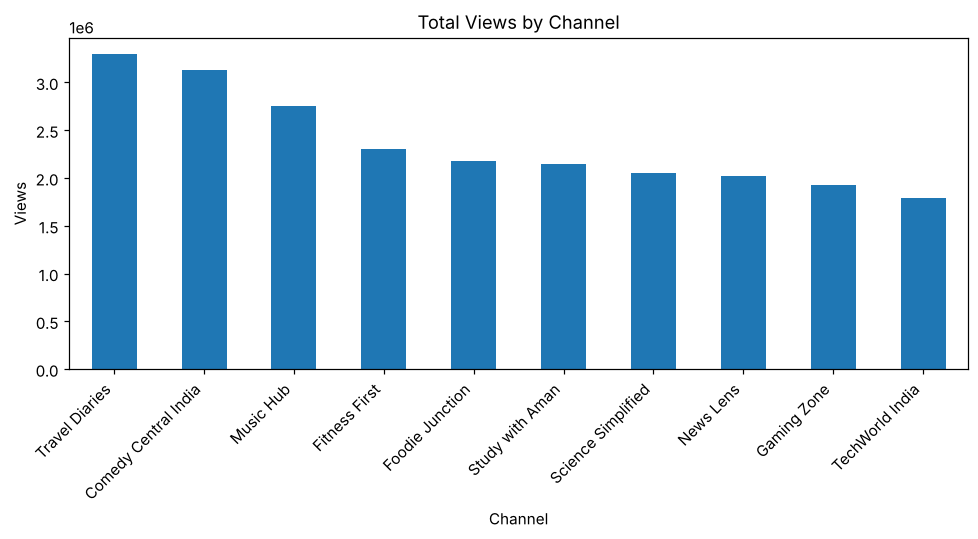

In [15]:
channel_views.plot(kind="bar", title="Total Views by Channel", ylabel="Views", figsize=(9, 5))
plt.xlabel("Channel")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 16 – Visualize views and engagement by category

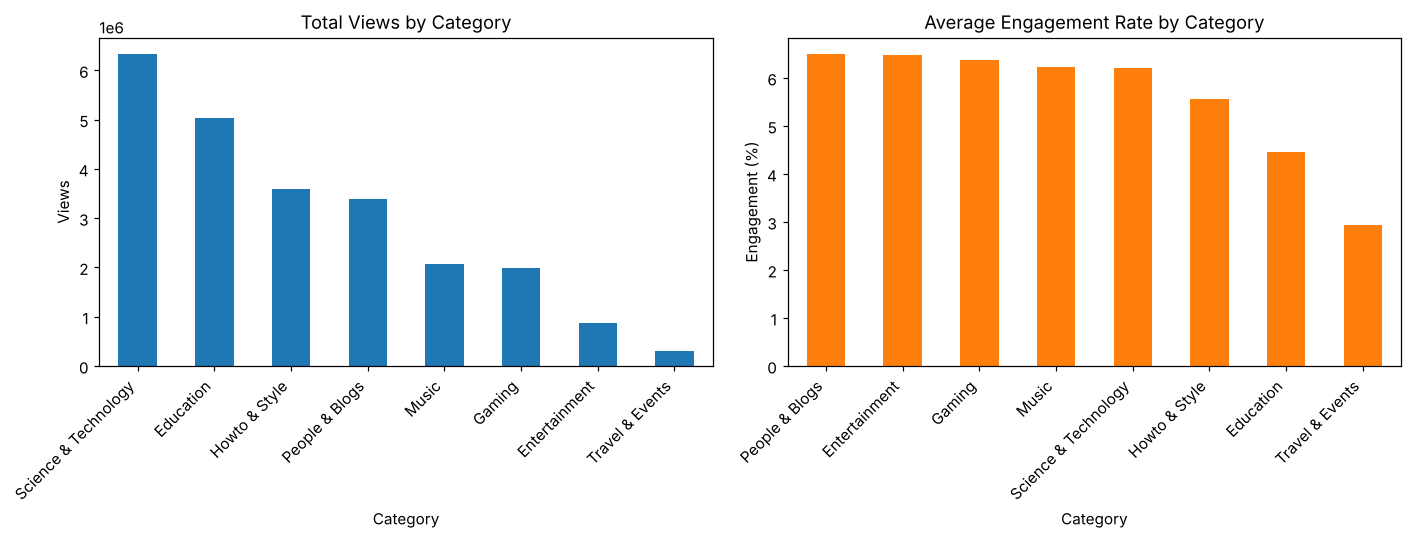

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

category_views.plot(kind="bar", ax=axes[0], title="Total Views by Category", ylabel="Views")
category_engagement.plot(kind="bar", ax=axes[1], title="Average Engagement Rate by Category", ylabel="Engagement (%)", color="tab:orange")

for ax in axes:
    ax.set_xlabel("Category")
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha("right")

plt.tight_layout()
plt.show()

## Step 17 – Visualize monthly trend

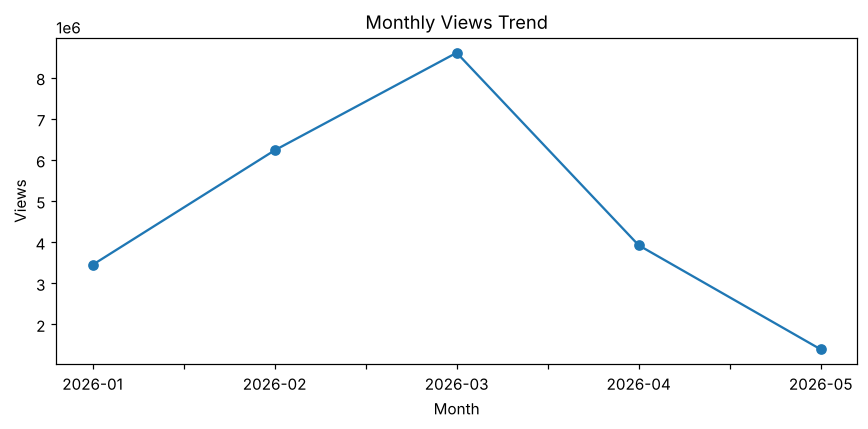

In [17]:
monthly_views.plot(kind="line", marker="o", title="Monthly Views Trend", ylabel="Views", figsize=(8, 4))
plt.xlabel("Month")
plt.tight_layout()
plt.show()

## Step 18 – Export cleaned data and summary reports
These files will be saved in the notebook's current working folder.

In [18]:
df.to_csv("youtube_videos_cleaned.csv", index=False)
channel_views.to_csv("views_summary_by_channel.csv", header=["Views"])
category_views.to_csv("views_summary_by_category.csv", header=["Views"])
monthly_views.to_csv("monthly_views_summary.csv", header=["Views"])

print("Export complete!")

Export complete!


## Step 19 – Student interpretation
Ask students to write 4–5 business observations:

1. Which channel got the most views?
2. Which channel has the best engagement rate?
3. Which category got the most views?
4. Which month had the highest views?
5. What data quality problems were found, and how were they handled?

**Important:** The cleaning choices in this notebook are teaching assumptions. In a real project, confirm business rules with the data owner before deleting or replacing records.

In [19]:
# Helper: quick answers to compare with your own observations
print("1. Most views (channel):", channel_views.idxmax())
print("2. Best engagement (channel):", channel_engagement.idxmax())
print("3. Most views (category):", category_views.idxmax())
print("4. Best month:", monthly_views.idxmax())

# Data quality check: do category labels match the channel?
print("\n5. Categories used by each channel:")
display(df.groupby("Channel_Name")["Category"].apply(lambda s: ", ".join(sorted(s.unique()))))

1. Most views (channel): Travel Diaries
2. Best engagement (channel): News Lens
3. Most views (category): Science & Technology
4. Best month: 2026-03

5. Categories used by each channel:


Channel_Name
Comedy Central India       Education, Gaming, Music, Science & Technology
Fitness First                     Education, Gaming, Howto & Style, Music
Foodie Junction         Entertainment, Gaming, People & Blogs, Science...
Gaming Zone             Education, Entertainment, Howto & Style, Peopl...
Music Hub               Education, Gaming, People & Blogs, Science & T...
News Lens               Education, Gaming, Howto & Style, People & Blo...
Science Simplified      Education, Howto & Style, People & Blogs, Trav...
Study with Aman         Entertainment, Howto & Style, People & Blogs, ...
TechWorld India            Education, Howto & Style, Science & Technology
Travel Diaries             Education, Howto & Style, Science & Technology
Name: Category, dtype: str

### My observations (Step 19)

1. **Highest-view channel:** *Travel Diaries* got the most views (3,301,294), about 14% of all 23.6 million views in the sample.
2. **Best engagement:** *News Lens* has the best average engagement rate (7.21%). *Science Simplified* is lowest (4.10%). Having many views does not mean high engagement: the correlation between Views and Engagement Rate is almost zero (-0.02).
3. **Category:** *Science & Technology* got the most views (6.34M) and *Education* is second (5.03M), but Education has low engagement (4.46%). *People & Blogs* has the best engagement (6.51%). *Travel & Events* looks weakest, but it has only 2 videos, so the comparison is not fair.
4. **Month:** *March 2026* had the highest views (8.61M), but it also had the most videos (17). Average views per video stay roughly the same every month (about 436K to 506K), so March was higher because more videos were published, not because each video performed better. May has only 3 videos (data ends on 14 May).
5. **Data quality:** No exact duplicates, no repeated Video_IDs, no missing values, and the engagement rate in the file matches (Likes + Comments) / Views x 100, so no rows were removed. The real problem is **category labels**: they do not match the channel (for example, the food video "Easy paneer recipe" is labelled *Gaming*, and "Exam preparation tips" is labelled *Travel & Events*). Category-level results should be treated carefully. The data is also DEMO/sample data, not real YouTube statistics.

**Recommendation:** Publish regularly (volume drove the best month), copy the style of high-engagement channels such as News Lens, and fix category labels before using this analysis for real decisions.